In [6]:
from pathlib import Path
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array


# Configurations
IMAGE_SIZE = (224, 224)
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Resolve the project root even when the notebook is started from a different working directory.
BASE_DIR = Path.cwd().resolve()
for candidate in [BASE_DIR, *BASE_DIR.parents]:
    if (candidate / "vampire_dairies_dataset").exists():
        BASE_DIR = candidate
        break

DATASET_DIR = BASE_DIR / "vampire_dairies_dataset"
DEFAULT_PREDICT_IMAGE = next(
    (
        path for path in [
            BASE_DIR / "Aishwarya.jpg.jpeg",
            BASE_DIR / "aishwarya.jpg",
            BASE_DIR / "Aishwarya.jpg",
            DATASET_DIR / "Aishwarya.jpg.jpeg",
        ]
        if path.exists()
    ),
    BASE_DIR / "Aishwarya.jpg.jpeg",
)
MODEL_PATH = BASE_DIR / "vgg16_image_recognition.keras"

print("Setup complete. Base directory:", BASE_DIR)


Setup complete. Base directory: C:\Users\Admin\Downloads\Deep-Learning-Image-Recognition-with-VGG16-master\Deep-Learning-Image-Recognition-with-VGG16-master


In [2]:
def get_training_data(dataset_dir: Path):
    """Load flat-folder images; filename stem is the class label."""
    if not dataset_dir.exists():
        raise FileNotFoundError(
            f"Dataset folder not found: {dataset_dir}\n"
            "Create a folder named 'vampire_dairies_dataset' in your working directory "
            "and put your training images inside it."
        )

    files = sorted(
        p for p in dataset_dir.iterdir()
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
    )
    if len(files) < 2:
        raise ValueError(
            f"Found {len(files)} usable image(s) in {dataset_dir}. "
            "Add at least two training images."
        )

    images, labels, class_names = [], [], []
    for file_path in files:
        class_name = file_path.stem
        try:
            pil_img = load_img(file_path, target_size=IMAGE_SIZE, color_mode="rgb")
            arr = img_to_array(pil_img)
            images.append(arr)
            labels.append(class_name)
            class_names.append(class_name)
        except Exception as exc:
            print(f"Skipping unreadable image {file_path.name}: {exc}")

    if len(images) < 2:
        raise ValueError("Not enough readable images were found in the dataset.")

    unique_names = sorted(set(labels))
    label_to_index = {name: i for i, name in enumerate(unique_names)}
    y = np.array([label_to_index[name] for name in labels], dtype=np.int32)
    x = np.array(images, dtype=np.float32)
    return x, y, unique_names, files

In [7]:
### **Cell 3: Model Architecture Builder**
def build_model(number_of_classes: int):
    base_model = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3),
    )
    base_model.trainable = False

    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(256, activation="relu"),
        Dropout(0.3),
        Dense(number_of_classes, activation="softmax"),
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [9]:
### **Cell 4: Train the Model**
def train_model(dataset_dir: Path):
    x, y, class_names, files = get_training_data(dataset_dir)
    print(f"Training images found: {len(files)}")
    print(f"Classes: {', '.join(class_names)}")

    # VGG16 expects inputs preprocessed with its own preprocessing function.
    x = preprocess_input(x.copy())

    model = build_model(len(class_names))

    # Augment the very small dataset during training.
    augmenter = ImageDataGenerator(
        rotation_range=15,
        width_shift_range=0.08,
        height_shift_range=0.08,
        zoom_range=0.10,
        horizontal_flip=True,
    )
    model.fit(
        augmenter.flow(x, y, batch_size=min(8, len(x)), shuffle=True),
        epochs=10,
        steps_per_epoch=max(1, len(x)),
        verbose=1,
    )

    model.save(MODEL_PATH)
    print(f"Model saved to: {MODEL_PATH}")
    return model, class_names


In [12]:
# Execute training
model, class_names = train_model(DATASET_DIR)

Training images found: 2
Classes: Aishwarya.jpg, Anushka.jpg
Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5000 - loss: 1.5516
Epoch 2/10


c:\Users\Admin\Downloads\Deep-Learning-Image-Recognition-with-VGG16-master\.venv-1\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.2365  
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.1344  
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.2095  
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5000 - loss: 0.8777  
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5000 - loss: 0.8606  
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.2490  
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.0317  
Epoch 9/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.1040  
Epoch 10/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5000 - loss: 1.5412  
Model saved to: C:\Users\Admin\Downloads\Deep-Learning-Image-Recognition-with-VGG16-master\Deep-Learning-Image-Recognition-with-VGG16-master\vgg16_image_recognition.keras


In [13]:
### **Cell 5: Predict Image and Display Results**
def predict_image(model, class_names, image_path: Path):
    if not image_path.exists():
        raise FileNotFoundError(
            f"Prediction image not found: {image_path}\n"
            "Place aishwarya.jpg in your working directory, or update DEFAULT_PREDICT_IMAGE."
        )

    pil_img = load_img(image_path, target_size=IMAGE_SIZE, color_mode="rgb")
    img_array = img_to_array(pil_img)
    batch = np.expand_dims(img_array, axis=0)
    batch = preprocess_input(batch)

    probabilities = model.predict(batch, verbose=0)[0]
    best_index = int(np.argmax(probabilities))
    predicted_name = class_names[best_index]
    confidence = float(probabilities[best_index]) * 100

    print("\n--- Prediction result ---")
    print(f"Image: {image_path.name}")
    print(f"Predicted class: {predicted_name}")
    print(f"Model score: {confidence:.2f}%")
    print("\nTop predictions:")
    for idx in np.argsort(probabilities)[::-1][:min(3, len(class_names))]:
        print(f"  {class_names[int(idx)]}: {probabilities[int(idx)] * 100:.2f}%")

    plt.figure(figsize=(5, 5))
    plt.imshow(pil_img)
    plt.title(f"Prediction: {predicted_name} ({confidence:.1f}%)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()



--- Prediction result ---
Image: Aishwarya.jpg.jpeg
Predicted class: Aishwarya.jpg
Model score: 97.54%

Top predictions:
  Aishwarya.jpg: 97.54%
  Anushka.jpg: 2.46%


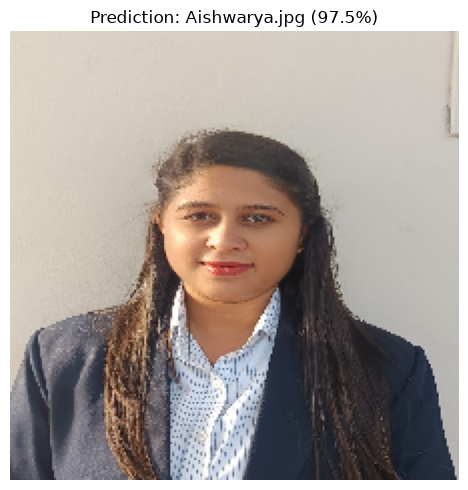

In [14]:
predict_image(model, class_names, DEFAULT_PREDICT_IMAGE)